Инициализация детектора (R=15 м, N=2000, r=10 см)...

--- 1. Проверка корректности (20 событий) ---
Среднее (Bruteforce): 114.3 ± 12.7
Среднее (Optimized):  100.9 ± 13.0
Относительная разница средних: 11.76%

--- 2. Сравнение скорости (10 событий) ---
Время (Bruteforce): 7.7887 сек
Время (Optimized):  0.8095 сек
Ускорение: 9.6x

--- 3. Симуляция 1000 событий для гистограммы ---


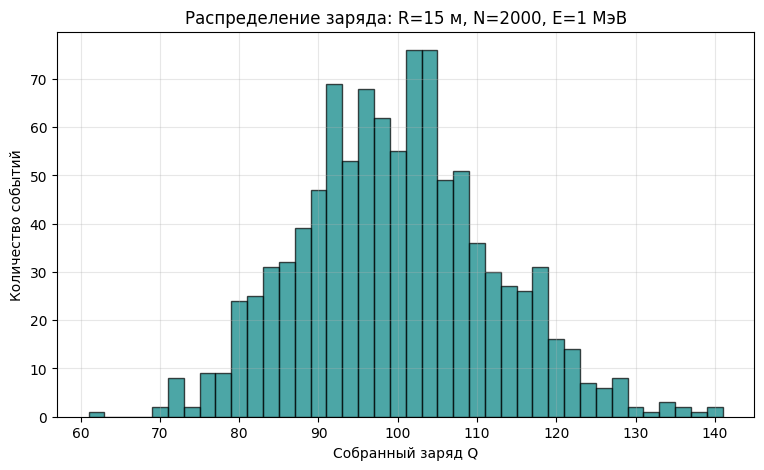

Итоговое среднее: 99.4 ± 12.2
Относительная ширина: 0.122


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import time

class LargeDetector:
    def __init__(self, R, r, N, a=0.5, Y=10000):
        self.R = R
        self.r = r
        self.N = N
        self.a = a
        self.Y = Y
        
        self.positions = self._place_pmt()
        
        self.n_theta_bins = 40
        self.n_phi_bins = 80
        self.grid = {}
        self._build_spatial_grid()

    def _place_pmt(self):
        points = []
        while len(points) < self.N:
            p = np.random.uniform(-1, 1, size=3)
            length = np.linalg.norm(p)
            if 0 < length <= 1:
                points.append(p / length * self.R)
        return np.array(points)

    def _build_spatial_grid(self):
        x, y, z = self.positions[:, 0], self.positions[:, 1], self.positions[:, 2]
        theta = np.arctan2(y, x)
        phi = np.arccos(np.clip(z / self.R, -1.0, 1.0))
        
        i_theta = np.clip(((theta + np.pi) / (2 * np.pi) * self.n_theta_bins).astype(int), 0, self.n_theta_bins - 1)
        i_phi = np.clip((phi / np.pi * self.n_phi_bins).astype(int), 0, self.n_phi_bins - 1)
        
        for idx in range(self.N):
            key = (i_theta[idx], i_phi[idx])
            if key not in self.grid:
                self.grid[key] = []
            self.grid[key].append(idx)

    def simulate_event_optimized(self, source_pos=(0.0, 0.0, 0.0), E=1.0):
        N_photons = int(E * self.Y)
        source_pos = np.array(source_pos)
        
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        cos_theta = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1 - cos_theta**2)
        directions = np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))
        
        hit_points = directions * self.R + source_pos
        
        x, y, z = hit_points[:, 0], hit_points[:, 1], hit_points[:, 2]
        theta = np.arctan2(y, x)
        phi = np.arccos(np.clip(z / self.R, -1.0, 1.0))
        
        i_theta = np.clip(((theta + np.pi) / (2 * np.pi) * self.n_theta_bins).astype(int), 0, self.n_theta_bins - 1)
        i_phi = np.clip((phi / np.pi * self.n_phi_bins).astype(int), 0, self.n_phi_bins - 1)
        
        num_hits_per_pmt = np.zeros(self.N, dtype=int)
        
        for (cell_theta, cell_phi), pmt_indices in self.grid.items():
            mask = (i_theta == cell_theta) & (i_phi == cell_phi)
            if not np.any(mask):
                continue
            
            local_hit_points = hit_points[mask]
            pmt_centers = self.positions[pmt_indices]
            
            dists = np.linalg.norm(local_hit_points[:, np.newaxis, :] - pmt_centers[np.newaxis, :, :], axis=2)
            hits = np.sum(dists <= self.r, axis=0)
            num_hits_per_pmt[pmt_indices] += hits
            
        electrons = np.random.poisson(self.a * num_hits_per_pmt)
        return np.sum(electrons)

def simulate_event_bruteforce(det, source_pos=(0.0, 0.0, 0.0), E=1.0):
    N_photons = int(E * det.Y)
    source_pos = np.array(source_pos)
    
    phi = np.random.uniform(0, 2 * np.pi, N_photons)
    cos_theta = np.random.uniform(-1, 1, N_photons)
    sin_theta = np.sqrt(1 - cos_theta**2)
    directions = np.column_stack((sin_theta * np.cos(phi), sin_theta * np.sin(phi), cos_theta))
    
    hit_points = directions * det.R + source_pos
    
    diffs = hit_points[:, np.newaxis, :] - det.positions[np.newaxis, :, :]
    dists = np.linalg.norm(diffs, axis=2)
    hits_mask = dists <= det.r
    num_hits_per_pmt = np.sum(hits_mask, axis=0)
    
    electrons = np.random.poisson(det.a * num_hits_per_pmt)
    return np.sum(electrons)

if __name__ == "__main__":
    print("Инициализация детектора (R=15 м, N=2000, r=10 см)...")
    det = LargeDetector(R=15.0, r=0.1, N=2000, a=0.5, Y=10000)
    
    print("\n--- 1. Проверка корректности (20 событий) ---")
    N_test = 20
    charges_opt = []
    charges_brute = []
    
    for _ in range(N_test):
        charges_opt.append(det.simulate_event_optimized())
        charges_brute.append(simulate_event_bruteforce(det))
        
    mean_opt, std_opt = np.mean(charges_opt), np.std(charges_opt)
    mean_brute, std_brute = np.mean(charges_brute), np.std(charges_brute)
    
    print(f"Среднее (Bruteforce): {mean_brute:.1f} ± {std_brute:.1f}")
    print(f"Среднее (Optimized):  {mean_opt:.1f} ± {std_opt:.1f}")
    err = abs(mean_brute - mean_opt) / mean_brute * 100
    print(f"Относительная разница средних: {err:.2f}%")
    
    print("\n--- 2. Сравнение скорости (10 событий) ---")
    N_bench = 10
    
    start = time.time()
    for _ in range(N_bench):
        simulate_event_bruteforce(det)
    time_brute = time.time() - start
    
    start = time.time()
    for _ in range(N_bench):
        det.simulate_event_optimized()
    time_opt = time.time() - start
    
    print(f"Время (Bruteforce): {time_brute:.4f} сек")
    print(f"Время (Optimized):  {time_opt:.4f} сек")
    print(f"Ускорение: {time_brute / time_opt:.1f}x")
    
    print("\n--- 3. Симуляция 1000 событий для гистограммы ---")
    charges_hist = []
    for _ in range(1000):
        charges_hist.append(det.simulate_event_optimized())
        
    plt.figure(figsize=(9, 5))
    plt.hist(charges_hist, bins=40, edgecolor='black', alpha=0.7, color='teal')
    plt.xlabel('Собранный заряд Q')
    plt.ylabel('Количество событий')
    plt.title('Распределение заряда: R=15 м, N=2000, E=1 МэВ')
    plt.grid(alpha=0.3)
    plt.show()
    
    print(f"Итоговое среднее: {np.mean(charges_hist):.1f} ± {np.std(charges_hist):.1f}")
    print(f"Относительная ширина: {np.std(charges_hist) / np.mean(charges_hist):.3f}")